# 02 - Cohort retention

**Goal.** Measure which share of new players come back 1, 7 and 14 days after their first day (D1, D7, D14), overall and by platform and country.

**Two traps handled here.**
1. *Who is a new player?* The window starts on 2025-02-28, so "first seen" is not "installed". A new player is a player with a `firstOpen` event (the install event) inside the window.
2. *Who can be observed?* A player who arrives on 2025-04-08 cannot have a D14. Each metric only uses cohorts old enough to be observed.

In [1]:
import sys
sys.path.append("../scripts")
from load_events import connect_events
import matplotlib.pyplot as plt
from statsmodels.stats.proportion import proportion_confint

con, readable, unreadable = connect_events("../data/raw/player_analytics/*.parquet")
print(len(readable), "readable files,", len(unreadable), "unreadable")

# The data ends on 2025-04-10 at 20:37, so that day is incomplete: the last full day is 2025-04-09.
LAST_FULL_DAY = "2025-04-09"
# 2025-03-27 is a data gap (section 5): a retention measured on that day would look like churn.
GAP_DAY = "2025-03-27"

67 readable files, 1 unreadable


## 1. Who is a new player?

Players with a `firstOpen` event are installs seen in the window. `_identityCreate` is another candidate; both are compared.

In [2]:
con.sql("""
    WITH f  AS (SELECT user_id, COUNT(*) AS n FROM events WHERE event_name = 'firstOpen' GROUP BY 1),
         i  AS (SELECT DISTINCT user_id FROM events WHERE event_name = '_identityCreate')
    SELECT (SELECT COUNT(DISTINCT user_id) FROM events)         AS players,
           (SELECT COUNT(*) FROM f)                              AS with_first_open,
           (SELECT MAX(n) FROM f)                                AS max_first_open_per_player,
           (SELECT COUNT(*) FROM i)                              AS with_identity_create,
           (SELECT COUNT(*) FROM f JOIN i USING (user_id))       AS in_both
""").show(max_width=200)

┌─────────┬─────────────────┬───────────────────────────┬──────────────────────┬─────────┐
│ players │ with_first_open │ max_first_open_per_player │ with_identity_create │ in_both │
│  int64  │      int64      │           int64           │        int64         │  int64  │
├─────────┼─────────────────┼───────────────────────────┼──────────────────────┼─────────┤
│   71679 │           48307 │                         2 │                50881 │   48303 │
└─────────┴─────────────────┴───────────────────────────┴──────────────────────┴─────────┘



Players with `firstOpen` form the cohort. The other players are returning players whose install happened before 2025-02-28; they are not part of retention by cohort. If `max_first_open_per_player` is above 1, a player reinstalled: the earliest `firstOpen` is kept.

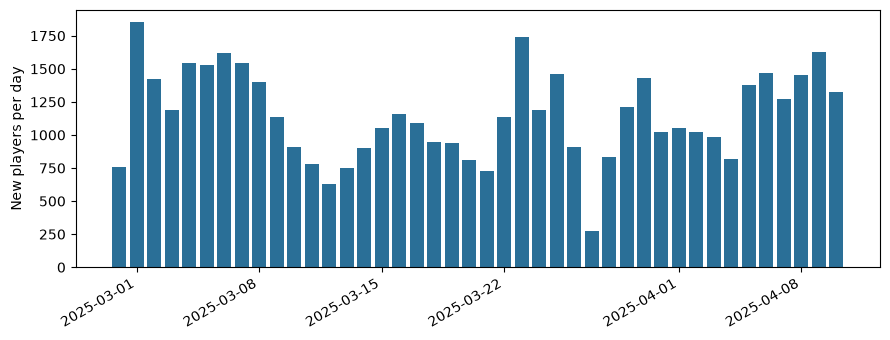

,cohort_day,new_players
0,2025-02-28,761
1,2025-03-01,1852
2,2025-03-02,1420


In [3]:
con.execute("""
    CREATE OR REPLACE TABLE new_players AS
    SELECT user_id,
           CAST(MIN(ts) AS DATE)             AS cohort_day,
           ANY_VALUE(NULLIF(client_platform, '')) AS platform,
           ANY_VALUE(NULLIF(country_code, ''))    AS country
    FROM events
    WHERE event_name = 'firstOpen'
    GROUP BY 1
""")
con.execute("""
    CREATE OR REPLACE TABLE active_days AS
    SELECT DISTINCT user_id, CAST(ts AS DATE) AS day
    FROM events
""")
df_coh = con.execute("SELECT cohort_day, COUNT(*) AS new_players FROM new_players GROUP BY 1 ORDER BY 1").df()
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(df_coh["cohort_day"], df_coh["new_players"], color="#2a6f97")
ax.set_ylabel("New players per day")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()
df_coh.head(3)

If the first bars are much taller than the others, the cohort definition leaks returning players. `firstOpen` should give a smooth series.

## 2. Retention D1, D7, D14

A player is retained on day N if they have at least one event exactly N days after their first day. "Active" therefore means any event, including background events: this can overstate real play (checked just below).

Cohorts whose day N falls on 2025-03-27 are left out of day N: that day is a data gap (section 5), and counting it would look like churn.

In [ ]:
def retention(n, by=None, activity="active_days"):
    """Retention on day n for cohorts old enough to be observed, with a 95% Wilson interval.

    activity: table of (user_id, day) pairs that count as an active day.
    """
    sel = f"p.{by} AS segment," if by else ""
    sql = f"""
        SELECT {sel}
               COUNT(*) AS players,
               COUNT(a.user_id) AS retained
        FROM new_players p
        LEFT JOIN {activity} a ON a.user_id = p.user_id AND a.day = p.cohort_day + {n}
        WHERE p.cohort_day + {n} <= DATE '{LAST_FULL_DAY}'
          AND p.cohort_day + {n} <> DATE '{GAP_DAY}'
        {"GROUP BY 1" if by else ""}
    """
    df = con.execute(sql).df()
    df = df[df["players"] > 0].copy()
    df["pct"] = (100 * df["retained"] / df["players"]).round(1)
    ci = [proportion_confint(r, p, method="wilson") for r, p in zip(df["retained"], df["players"])]
    df["ci_low"] = [round(100 * c[0], 1) for c in ci]
    df["ci_high"] = [round(100 * c[1], 1) for c in ci]
    df.insert(0, "day_n", n)
    return df

import pandas as pd
overall = pd.concat([retention(n) for n in (1, 7, 14)], ignore_index=True)
overall

### Sensitivity check: what counts as an active day?

Some events have no session id and look server-side (`achievementUpdated`, `currencyGranted`, `_propertiesUpdate`, ...). If one of them can be recorded on a day when the player did not open the game, "any event" overstates retention. The same retention is computed with a stricter definition: at least one `_sessionStart` (a session opened) on that day.

In [ ]:
con.execute("""
    CREATE OR REPLACE TABLE session_days AS
    SELECT DISTINCT user_id, CAST(ts AS DATE) AS day
    FROM events
    WHERE event_name = '_sessionStart'
""")
strict = pd.concat([retention(n, activity="session_days") for n in (1, 7, 14)], ignore_index=True)
comparison = overall[["day_n", "players", "pct"]].merge(
    strict[["day_n", "pct"]], on="day_n", suffixes=("_any_event", "_session_start"))
comparison["gap_points"] = (comparison["pct_any_event"] - comparison["pct_session_start"]).round(1)
comparison

If `gap_points` stays below about one point, the definition does not change the conclusions. If it is larger, the stricter definition should be used for the headline figures.

## 3. By platform and country

Only segments with at least 500 new players are shown: below that, percentages are unstable. When two intervals overlap, there is no clear difference.

In [ ]:
by_platform = pd.concat([retention(n, "platform").assign(day_n=n) for n in (1, 7, 14)], ignore_index=True)
by_platform[by_platform["players"] >= 500].sort_values(["day_n", "segment"])

In [ ]:
top = con.execute("SELECT country FROM new_players GROUP BY 1 HAVING COUNT(*) >= 500 ORDER BY COUNT(*) DESC LIMIT 8").df()["country"].tolist()
by_country = pd.concat([retention(n, "country").assign(day_n=n) for n in (1, 7, 14)], ignore_index=True)
by_country = by_country[by_country["segment"].isin(top) & (by_country["players"] >= 500)]
by_country.sort_values(["day_n", "pct"], ascending=[True, False])

## 4. Retention curve, D0 to D14

One point per day since the first day, computed on cohorts observable for the whole 14 days.

In [ ]:
curve = pd.concat([retention(n) for n in range(1, 15)], ignore_index=True)
# note: later days use fewer cohorts, so the curve mixes slightly different cohorts
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(curve["day_n"], curve["pct"], marker="o", color="#2a6f97")
ax.fill_between(curve["day_n"], curve["ci_low"], curve["ci_high"], alpha=0.2, color="#2a6f97")
ax.set_xlabel("Days since first day")
ax.set_ylabel("Players active (%)")
ax.set_ylim(0, 100)
plt.tight_layout()
plt.show()
curve[["day_n", "players", "pct"]]

## 5. Does the 2025-03-27 drop affect retention?

D1 for the cohort of 2025-03-26 is measured on 2025-03-27, the day with a third of the usual active players. If it is much lower than its neighbours, the drop is missing data, not players leaving.

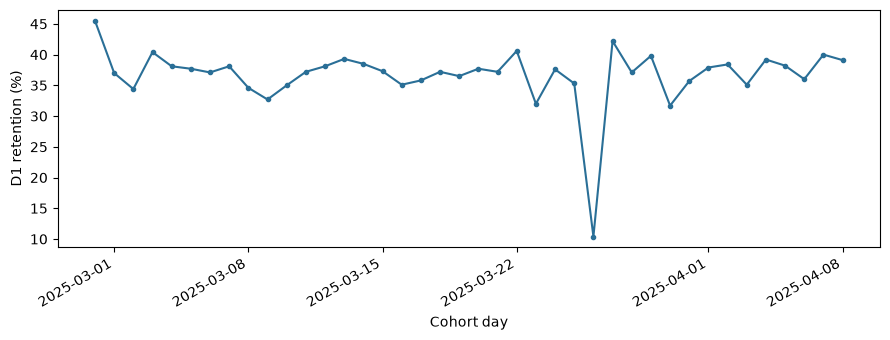

,cohort_day,players,d1_pct
24,2025-03-24,1185,37.6
25,2025-03-25,1463,35.3
26,2025-03-26,906,10.4
27,2025-03-27,277,42.2
28,2025-03-28,833,37.1
29,2025-03-29,1208,39.8


In [8]:
df_d1 = con.execute("""
    SELECT p.cohort_day,
           COUNT(*) AS players,
           ROUND(100.0 * COUNT(a.user_id) / COUNT(*), 1) AS d1_pct
    FROM new_players p
    LEFT JOIN active_days a ON a.user_id = p.user_id AND a.day = p.cohort_day + 1
    WHERE p.cohort_day + 1 <= DATE '2025-04-09'
    GROUP BY 1 ORDER BY 1
""").df()
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(df_d1["cohort_day"], df_d1["d1_pct"], marker=".", color="#2a6f97")
ax.set_ylabel("D1 retention (%)")
ax.set_xlabel("Cohort day")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()
df_d1[df_d1["cohort_day"].astype(str).between("2025-03-24", "2025-03-29")]

## 6. Funnel for new players only

Same five steps as notebook 01, but only for new players, so earlier progress cannot fall outside the window.

In [9]:
STEPS = ["gameOpened", "tokenCashout", "deviceUnlocked", "zoneUnlocked", "purchaseCompleted"]
names = ", ".join(f"'{s}'" for s in STEPS)
con.execute(f"""
    CREATE OR REPLACE TABLE firsts_new AS
    SELECT e.user_id, e.event_name, MIN(e.ts) AS t
    FROM events e JOIN new_players p USING (user_id)
    WHERE e.event_name IN ({names})
    GROUP BY 1, 2
""")
con.execute("CREATE OR REPLACE TABLE funnel_new AS SELECT user_id, t, 1 AS step FROM firsts_new WHERE event_name = ?", [STEPS[0]])
for k in range(1, len(STEPS)):
    con.execute(f"""
        INSERT INTO funnel_new
        SELECT f.user_id, f.t, {k + 1}
        FROM firsts_new f
        JOIN funnel_new p ON p.user_id = f.user_id AND p.step = {k} AND f.t >= p.t
        WHERE f.event_name = '{STEPS[k]}'
    """)
df_f = con.execute("SELECT step, COUNT(*) AS players FROM funnel_new GROUP BY 1 ORDER BY 1").df()
df_f["event"] = STEPS[: len(df_f)]
df_f["pct_of_previous"] = (100 * df_f["players"] / df_f["players"].shift(1)).round(1)
df_f["pct_of_first"] = (100 * df_f["players"] / df_f["players"].iloc[0]).round(1)
df_f[["event", "players", "pct_of_previous", "pct_of_first"]]

,event,players,pct_of_previous,pct_of_first
0,gameOpened,48288,NaN,100.0
1,tokenCashout,46918,97.2,97.2
2,deviceUnlocked,46048,98.1,95.4
3,zoneUnlocked,45650,99.1,94.5
4,purchaseCompleted,720,1.6,1.5


In [ ]:
# purchaseCompleted only exists for Android players (docs/tracking_plan.md, finding 11),
# so the purchase step is also measured on Android new players alone.
con.sql("""
    SELECT COUNT(*)                                      AS android_players_who_opened,
           COUNT(f.user_id)                              AS purchasers,
           ROUND(100.0 * COUNT(f.user_id) / COUNT(*), 1) AS purchase_pct
    FROM new_players p
    JOIN funnel_new s      ON s.user_id = p.user_id AND s.step = 1
    LEFT JOIN funnel_new f ON f.user_id = p.user_id AND f.step = 5
    WHERE p.platform = 'Android'
""").show()

## Findings

- **Cohorts.** 48,307 of the 71,679 players have a `firstOpen` event (one player has two: reinstall); the other 23,000 or so installed before 2025-02-28 and are not in the cohorts. Cohort sizes are smooth (about 600 to 1,850 new players per day); the first day (761) is partial.
- **Retention.** D1 is 37.0% (95% interval 36.6 to 37.5, 44,447 players), D7 is 6.7% (6.4 to 7.0, 37,161 players) and D14 is 2.9% (2.8 to 3.1, 30,373 players). The curve falls fast: 20.9% on day 2 and 14.4% on day 3, then flattens.
- **Platform.** iPhone players retain better than Android players on D1 (40.5% against 35.6%) and on D7 (7.5% against 6.4%): the intervals do not overlap. On D14 (3.2% against 2.8%) they overlap, so there is no clear difference. The reason is not known (players, device, version or ads may differ).
- **Country.** On D1 the eight largest countries range from 34.7% (SA) to 42.4% (TH), and the intervals of TH and SA do not overlap. Countries differ in platform mix, which was not controlled, and eight countries times three days makes many comparisons: treat country differences as leads, not findings.
- **The 2025-03-27 drop is a data gap, not players leaving.** The D1 of the 2025-03-26 cohort is 10.4% against 35 to 38% for its neighbours, and only 277 new players are seen on 2025-03-27 (against 600 to 1,850 on other days). Everyone seems affected, and the next cohorts return to 37 to 42%. This is consistent with missing events on that day; the cause (outage, tracking) remains unknown. For this reason every retention figure above leaves out the cohorts whose day N falls on 2025-03-27.
- **Funnel for new players.** 48,288 players opened the game; 97.2% reached `tokenCashout`, 98.1% of those `deviceUnlocked`, 99.1% of those `zoneUnlocked`, and 1.5% (720 players) `purchaseCompleted`. Almost no one is lost before the purchase, so these steps probably belong to a guided start and do not discriminate between players. `purchaseCompleted` is recorded for Android players only, so the purchase step is also measured on Android new players alone (table above): the iPhone players, who cannot have this event, are removed from the denominator. The funnel in notebook 01 (all players) understated steps 3 and 4 for returning players, as expected.

**Limits.**
- "Active" means at least one event, including background events; section 2 compares it with a stricter definition (a session opened that day).
- Players without a `firstOpen` event are excluded from the cohorts, so the cohorts describe installs seen in the window only.
- The window is six weeks long: D14 only covers cohorts up to 2025-03-26.
- iPhone purchases are not visible in `purchaseCompleted`: no purchase rate can be given for iPhone players.